# Clase 12 — PCA y Series Temporales
## Una empresa de suplementos: ¿cómo resumimos el negocio y cuánto stock compramos?

---

Somos el **equipo de analítica de una empresa de suplementos deportivos con venta online**. La gerencia nos hace dos pedidos distintos:

1. *"Tenemos un tablero diario con 16 indicadores y no hay forma de mirarlos todos juntos. ¿Se puede resumir sin perder lo importante?"* → **PCA**.
2. *"Tenemos que decidir cuánto stock comprar para los próximos tres meses."* → **Series temporales**.

Si compramos de más, tenemos plata inmovilizada en el depósito. Si compramos de menos, perdemos ventas. Y para decidir bien, no alcanza con mirar el promedio: hay que saber **para dónde va el negocio y qué le pasa en cada época del año**.

**Un solo dataset, dos lentes.** En la primera parte cada día es una foto independiente con 16 variables: acá el orden de las filas no importa (podríamos mezclarlas y el PCA daría lo mismo). En la segunda parte miramos el mismo dato como una película: acá **el orden lo es todo**. Las dos partes son independientes: no usamos los componentes del PCA para pronosticar.

**Datos:** son **simulados** (no es una empresa real), armados para parecerse a un e-commerce argentino de suplementos: **1.826 días** (del 1/4/2021 al 31/3/2026) y 16 indicadores del negocio, más un campo `evento` que marca los días de Hot Sale, Cyber Monday y Black Friday. Todo lo monetario está en **dólares**, para no arrastrar el efecto de la inflación (que sería otro problema, y no es el de hoy).

**Veníamos de la Clase 11.** Cerramos esa clase con una pregunta: *¿y si pudiéramos resumir seis variables en dos nuevas, que conserven lo más importante?* Eso es PCA, y arrancamos por ahí.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX

sns.set_style("whitegrid")
COLORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]

---
# Parte A — PCA: resumir 16 indicadores en pocos componentes

## 1. Carga y vistazo

Antes de resumir, miramos qué mide cada columna y en qué magnitudes. Los 16 indicadores se agrupan en cuatro familias:

| Familia | Indicadores |
|---|---|
| Tráfico y embudo de compra | `sesiones_web`, `usuarios_nuevos`, `visitas_producto`, `carritos_creados` |
| Ventas | `pedidos`, `unidades_vendidas`, `facturacion_usd`, `ticket_promedio_usd` |
| Marketing y precio | `inversion_ads_usd`, `impresiones_ads`, `clics_ads`, `descuento_promedio_pct` |
| Operación y servicio | `dias_entrega`, `consultas_soporte`, `devoluciones`, `nps` |

`evento` (ninguno, Hot Sale, Cyber Monday o Black Friday) **no entra al PCA**. Lo guardamos para el final, igual que hicimos con `canal` en la Clase 11: a ver si el algoritmo, sin conocerlo, descubre algo parecido.

In [2]:
suplementos = pd.read_csv("suplementos_diario.csv", parse_dates=["fecha"])

INDICADORES = [
    "sesiones_web", "usuarios_nuevos", "visitas_producto", "carritos_creados",
    "pedidos", "unidades_vendidas", "facturacion_usd", "ticket_promedio_usd",
    "inversion_ads_usd", "impresiones_ads", "clics_ads", "descuento_promedio_pct",
    "dias_entrega", "consultas_soporte", "devoluciones", "nps",
]

print(f"{len(suplementos)} días | {len(INDICADORES)} indicadores | "
      f"del {suplementos['fecha'].min():%d/%m/%Y} al {suplementos['fecha'].max():%d/%m/%Y}")
suplementos[INDICADORES].describe().round(1).T[["mean", "50%", "std", "max"]]

1826 días | 16 indicadores | del 01/04/2021 al 31/03/2026


,mean,50%,std,max
sesiones_web,4080.3,3831.5,1837.7,19538.0
usuarios_nuevos,1468.2,1377.5,666.4,7364.0
visitas_producto,12246.5,11527.5,5587.6,62676.0
carritos_creados,265.9,249.0,121.1,1356.0
pedidos,146.5,138.0,67.0,702.0
unidades_vendidas,337.9,316.0,154.6,1677.0
facturacion_usd,9925.2,9417.5,4063.6,33848.0
ticket_promedio_usd,68.4,68.6,4.9,84.6
inversion_ads_usd,1189.3,1161.5,394.3,4186.0
impresiones_ads,619287.8,599334.5,210392.8,2229265.0


**Mirá la columna `mean` de arriba abajo:** `sesiones_web` promedia unas 4.000, `impresiones_ads` unas 620.000 y `dias_entrega` apenas 2,4. Son magnitudes de órdenes completamente distintos. Guardate esa observación, porque en la sección 3 va a ser un problema para el algoritmo.

Mirá también la fila `max` contra la mediana (`50%`): en `sesiones_web` el máximo es cinco veces la mediana. Esos son los días de Hot Sale y Cyber Monday. No son errores de carga, son los días más importantes del año.

---
## 2. EDA: ¿qué tan redundante es el tablero?

El motivo de usar PCA es que **muchas variables dicen casi lo mismo**. Antes de resumirlas, comprobemos que es así. El mapa de calor muestra la correlación entre cada par de indicadores: rojo intenso es "suben y bajan juntos", azul es "cuando una sube la otra baja".

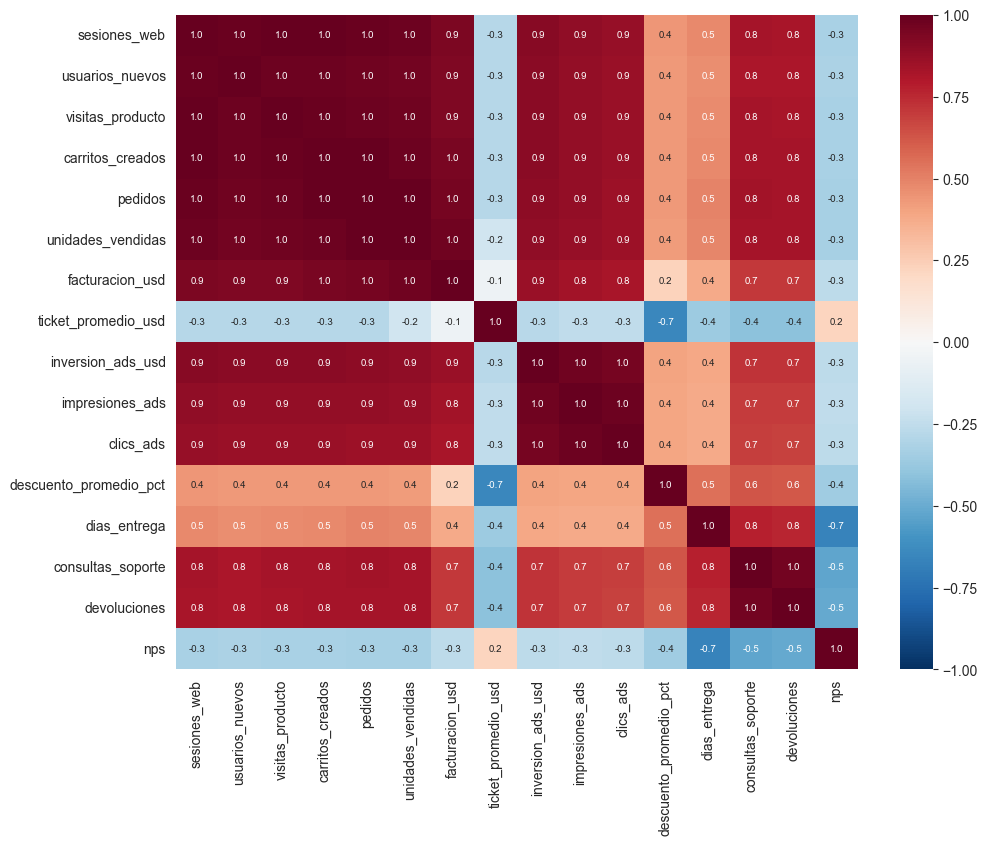

In [3]:
correlaciones = suplementos[INDICADORES].corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(correlaciones, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
plt.show()

In [4]:
parte_alta = np.triu_indices(len(INDICADORES), k=1)  # cada par una sola vez, sin la diagonal
pares = correlaciones.values[parte_alta]

print(f"Pares de indicadores: {len(pares)}")
print(f"Con correlación mayor a 0,9: {(pares > 0.9).sum()}")

Pares de indicadores: 120
Con correlación mayor a 0,9: 29


**Se ve un bloque rojo enorme:** tráfico, embudo, ventas y marketing están casi todos correlacionados por encima de 0,8 entre sí (`sesiones_web` y `pedidos`, por ejemplo, llegan a 0,985; el mapa lo redondea a 1,0). De los 120 pares posibles, 29 superan el 0,9. Tiene lógica de negocio: más sesiones, más carritos, más pedidos, más unidades; y en un día de Hot Sale sube todo junto. Una aclaración: parte de esta correlación viene de que todo crece con los años y con los eventos, no de que una variable cause a la otra.

Ahora mirá las filas de `ticket_promedio_usd` y `nps`: casi no se mueven con el volumen (colores suaves). Ahí hay información **distinta** al bloque grande.

Una pregunta para pensar: si `sesiones_web` y `pedidos` se mueven prácticamente 1 a 1, ¿cuánta información nueva suma mirar las dos? Esa redundancia es lo que PCA aprovecha.

---
## 3. Preparación: estandarizar (y por qué no hace falta tocar los extremos)

PCA busca las direcciones donde los datos **más varían**. El problema es que la varianza depende de la unidad de medida: una variable en cientos de miles tiene una varianza gigantesca, aunque no sea más "importante" que una en unidades. Es el mismo problema que tuvimos con KNN en la **Clase 05** y con K-Means en la **Clase 11**. Probemos qué pasa si lo corremos **sin** estandarizar:

In [5]:
X = suplementos[INDICADORES]

pca_sin_escalar = PCA().fit(X)
peso_pc1 = pd.Series(pca_sin_escalar.components_[0], index=INDICADORES).abs().sort_values(ascending=False)

print(f"PC1 sin estandarizar explica el {pca_sin_escalar.explained_variance_ratio_[0]:.2%} de la varianza")
peso_pc1.head(3).round(3)

PC1 sin estandarizar explica el 99.97% de la varianza


impresiones_ads     0.999
visitas_producto    0.023
clics_ads           0.017
dtype: float64

**Sin estandarizar, PC1 explica el 99,97% de la varianza, y casi todo su peso (0,999) está en una sola variable: `impresiones_ads`.** No es que las impresiones sean lo más importante del negocio: es la columna con los números más grandes. El PCA "resumió" el tablero mirando una sola columna, y las otras 15 prácticamente no existieron.

Por eso la regla del PDF es **SIEMPRE estandarizar antes de PCA**: cada variable pasa a "cuántos desvíos por encima o por debajo de su promedio está", y todas compiten en igualdad de condiciones.

**Una trampa conceptual.** Venimos de la Clase 04, donde el reflejo era sacar los outliers, y de la Clase 11, donde los domamos con logaritmo. Acá **no hacemos ninguna de las dos cosas**: los días de Hot Sale y Cyber Monday son la variación más importante del negocio, y justamente queremos que el PCA la vea. Si los sacáramos, el resumen no describiría los días que más le importan a la gerencia.

In [6]:
escalador = StandardScaler()
X_esc = pd.DataFrame(escalador.fit_transform(X), columns=INDICADORES)

X_esc.describe().loc[["mean", "std"]].round(2)

,sesiones_web,usuarios_nuevos,visitas_producto,carritos_creados,pedidos,unidades_vendidas,facturacion_usd,ticket_promedio_usd,inversion_ads_usd,impresiones_ads,clics_ads,descuento_promedio_pct,dias_entrega,consultas_soporte,devoluciones,nps
mean,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Los 16 indicadores quedaron con promedio 0 y desvío 1. De acá en adelante, todo el análisis usa `X_esc`.

Una aclaración para más adelante: acá ajustamos el escalador con **todos** los días porque solo estamos explorando, no prediciendo nada. En la sección 7, cuando sí haya un modelo que evaluar, el escalador y el PCA se ajustan **solo con train** (si no, es *data leakage*, como vimos en la Clase 06).

---
## 4. Modelo: ¿cuántos componentes nos quedamos?

El PCA hace por nosotros lo que describe el PDF (matriz de covarianza, autovalores y autovectores). Si querés la derivación, está en la teoría; acá lo vemos en acción. Lo que importa saber es el resultado: **16 componentes nuevos, ordenados de mayor a menor varianza explicada**, que no están correlacionados entre sí. Con 16 variables originales hay 16 componentes, pero **la gracia es quedarse con pocos**.

Cada componente trae un **ratio de varianza explicada**: qué porcentaje de la variación total del tablero captura. La pregunta es hasta cuántos nos conviene llegar.

In [7]:
pca = PCA().fit(X_esc)

nombres_pc = []
for i in range(1, len(INDICADORES) + 1):
    nombres_pc.append(f"PC{i}")

varianza = pd.DataFrame({
    "componente": nombres_pc,
    "varianza explicada (%)": pca.explained_variance_ratio_ * 100,
})
varianza["acumulada (%)"] = varianza["varianza explicada (%)"].cumsum()

varianza.head(6).round(1)

,componente,varianza explicada (%),acumulada (%)
0,PC1,72.2,72.2
1,PC2,12.6,84.7
2,PC3,6.3,91.1
3,PC4,3.0,94.1
4,PC5,2.2,96.3
5,PC6,1.7,98.0


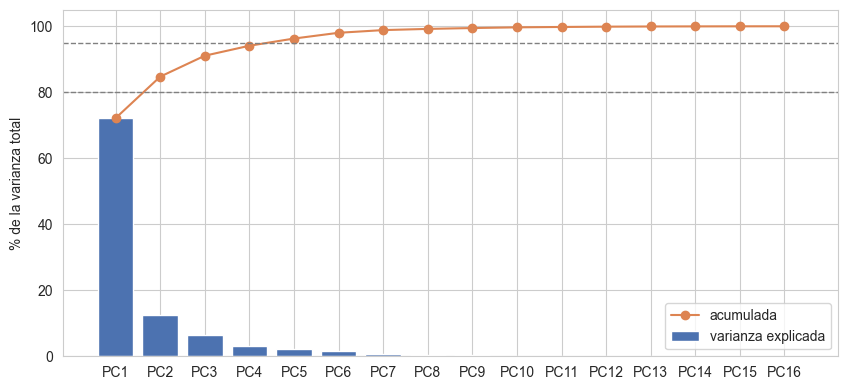

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(varianza["componente"], varianza["varianza explicada (%)"], color="#4C72B0", label="varianza explicada")
ax.plot(varianza["componente"], varianza["acumulada (%)"], marker="o", color="#DD8452", label="acumulada")
ax.axhline(80, color="gray", linestyle="--", linewidth=1)
ax.axhline(95, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("% de la varianza total")
ax.legend()
plt.show()

**PC1 explica el 72% de la variación del tablero.** Tiene sentido: casi todo el negocio sube y baja junto, así que una sola dirección ya captura la mayor parte. Con dos componentes llegamos al 85%, con tres al 91% y con cuatro al 94%. Los 12 componentes restantes suman menos del 6%. O sea que los 16 indicadores tienen 16 dimensiones en teoría, pero en la práctica **unas tres**.

Esta curva es la prima del codo de la Clase 11: en vez de buscar el quiebre, aplicamos la **regla práctica del PDF: quedarse con los componentes que acumulen entre 80% y 95%**. Las dos líneas punteadas marcan esos límites.

Y recordá el trade-off: cada componente de más suma información pero también suma complejidad. Menos componentes es más simple, pero más información perdida.

### Pausa: pizarrón 1 — ¿Cuántos componentes elegimos?

Escribimos 2, 3 y 4 en el pizarrón y votamos. Para decidir, no vale decir "la regla dice...". Pensemos en negocio:

- Si queremos **graficar** a los 1.826 días en un plano, necesitamos exactamente 2. ¿Alcanza con lo que explican?
- Si queremos **modelar** (sección 7), ¿nos conviene perder el 15% de la información o el 9%?
- ¿Y si el componente que agregamos es difícil de explicarle a la gerencia?

Con la decisión tomada, la escribimos en la variable `K` de la próxima celda.

In [9]:
K = 3  # lo decide la clase en el pizarrón

pca_k = PCA(n_components=K).fit(X_esc)
componentes = pd.DataFrame(pca_k.transform(X_esc), columns=nombres_pc[:K])

print(f"Con {K} componentes pasamos de {len(INDICADORES)} variables a {K}, "
      f"y conservamos el {pca_k.explained_variance_ratio_.sum():.1%} de la información")

Con 3 componentes pasamos de 16 variables a 3, y conservamos el 91.1% de la información


---
## 5. Interpretación: ¿qué significa cada componente?

Un componente es una **combinación lineal de las variables originales**: una receta que mezcla los 16 indicadores con distintos pesos. Esos pesos se llaman **loadings** y son lo único que nos permite ponerle nombre a un componente. Cuanto más lejos de cero (en rojo o en azul), más pesa esa variable en el componente.

Se lee **por columna**: una columna = el retrato de un componente.

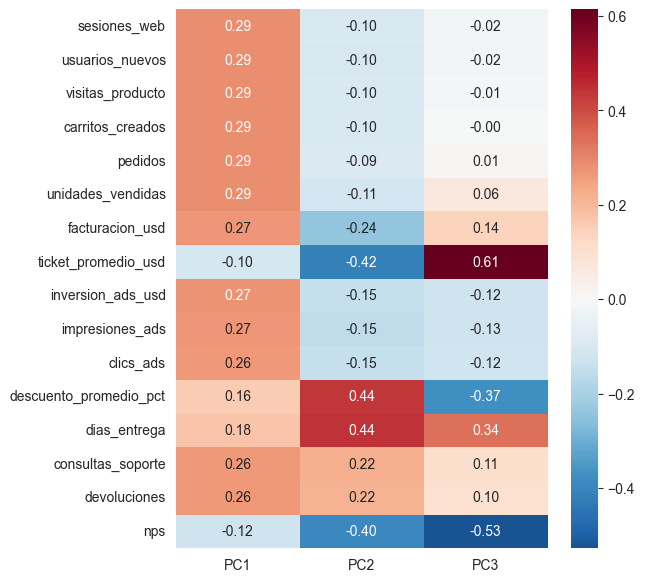

In [10]:
loadings = pd.DataFrame(pca_k.components_.T, index=INDICADORES, columns=nombres_pc[:K])

fig, ax = plt.subplots(figsize=(6, 7))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
plt.show()

**PC1 es el "nivel de actividad" del día.** Tráfico, embudo, ventas, marketing, consultas y devoluciones pesan parecido (entre 0,26 y 0,29) y con el mismo signo. Un día con PC1 alto es un día en que todo el negocio se mueve más: más visitas, más pedidos, más inversión y también más reclamos.

**PC2 es la "presión comercial y logística".** Pesan en positivo el descuento (0,44) y los días de entrega (0,44), y algo menos las consultas y devoluciones (0,22); en negativo el NPS (-0,40) y el ticket promedio (-0,42). La lectura: días de descuentos fuertes, entregas más lentas, más reclamos, clientes menos satisfechos y tickets más chicos. Un PC2 alto es mala noticia para la experiencia del cliente.

**PC3 ya no cuenta una historia tan limpia.** Contrapone el ticket promedio (0,61) y los días de entrega (0,34) con el NPS (-0,53) y el descuento (-0,37). Explica solo el 6% de la variación, y es lo esperable: cuanto más atrás en la fila, más difusos los componentes.

Dos advertencias de lectura:

- **El signo de un componente es arbitrario.** Si corrés el PCA en otra máquina, un componente puede salir con todos los signos dados vuelta. Lo que importa es la **relación entre signos**: qué variables van juntas y cuáles van en sentido contrario.
- **Interpretar es trabajo nuestro.** El algoritmo no sabe que PC1 es "actividad": solo sabe que un grupo de variables se mueve junto. El nombre lo pone una persona que conoce el negocio.

### Pausa: pizarrón 2 — ¿Cómo se llama cada componente?

Un nombre por componente, como en el ejemplo de la teoría ("Comportamiento de pago", "Tipo de cliente"). Para cada uno:

- ¿Qué variables pesan más, y qué tienen en común?
- ¿Qué nombre le pondrían para que lo entienda alguien de otra área?
- Si un día tiene un valor **alto** en ese componente, ¿es una buena o una mala noticia para el negocio?

Es normal que el último componente cueste más: cada uno explica menos que el anterior, y las historias se vuelven más difusas.

---
## 6. Visualización: los 1.826 días en un plano

Esta es la primera de las motivaciones del PDF: **graficar**. Con 16 variables era imposible; con dos componentes, cada día es un punto. Y ahora usamos la columna que el PCA nunca vio: `evento`. Si los componentes capturan algo real del negocio, los días especiales deberían quedar separados del resto.

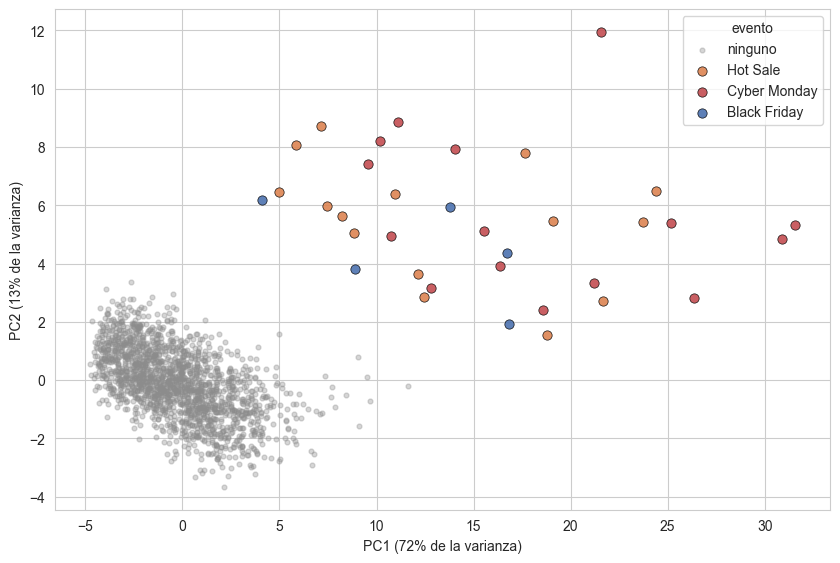

In [11]:
componentes["evento"] = suplementos["evento"]

pc1_pct = pca_k.explained_variance_ratio_[0] * 100
pc2_pct = pca_k.explained_variance_ratio_[1] * 100

fig, ax = plt.subplots(figsize=(10, 6.5))
dias_normales = componentes[componentes["evento"] == "ninguno"]
ax.scatter(dias_normales["PC1"], dias_normales["PC2"], s=12, alpha=0.35, color="#8C8C8C", label="ninguno")

colores_evento = {"Hot Sale": "#DD8452", "Cyber Monday": "#C44E52", "Black Friday": "#4C72B0"}
for nombre, color in colores_evento.items():
    dias = componentes[componentes["evento"] == nombre]
    ax.scatter(dias["PC1"], dias["PC2"], s=45, alpha=0.9, color=color, edgecolor="black", linewidth=0.5, label=nombre)

ax.set_xlabel(f"PC1 ({pc1_pct:.0f}% de la varianza)")
ax.set_ylabel(f"PC2 ({pc2_pct:.0f}% de la varianza)")
ax.legend(title="evento")
plt.show()

In [12]:
componentes.groupby("evento")[["PC1", "PC2"]].mean().round(1)

,PC1,PC2
evento,,
Black Friday,12.1,4.4
Cyber Monday,18.4,5.7
Hot Sale,13.6,5.5
ninguno,-0.3,-0.1


**Los días de evento quedan todos a la derecha y arriba**, separados de la nube gris de los días normales, que se amontona cerca del origen. A la derecha, porque PC1 mide actividad y un día de Hot Sale o Cyber Monday es de máxima actividad (PC1 promedio entre 12 y 18, contra -0,3 en los días sin evento). Arriba, porque PC2 mide presión comercial y logística, y en esos días hay descuentos fuertes y entregas más lentas.

**El PCA nunca vio la columna `evento`** y aun así separó esos días: es la señal de que los componentes capturan algo real del negocio. Con 16 variables no había forma de ver esto; con dos, se ve de un vistazo.

Fijate también en unos pocos días grises que se corren a la derecha (hasta casi PC1 = 12). No son un error: casi todos son días de enero de 2026, temporada alta con el negocio ya mucho más grande que en 2021. Eso es lo que vamos a estudiar en la Parte B: cómo cambia el negocio con el tiempo.

---
## 7. PCA como preprocesamiento: ¿con o sin?

Hasta ahora usamos PCA para **entender** el tablero. La otra gran motivación del PDF es **preprocesar** para un modelo: eliminar multicolinealidad y reducir variables. Y la cuarta consideración de la teoría dice: **comparar performance con y sin PCA**. Hagámoslo.

**La pregunta de negocio:** ¿qué mueve la satisfacción del cliente (`nps`)? Vamos a predecirla con los otros 15 indicadores usando una regresión lineal (Clase 05). Dos decisiones técnicas antes de empezar:

- **Train y test por fecha, no al azar.** Los días cercanos se parecen mucho entre sí; si mezclamos al azar, el modelo "ve" días vecinos del que tiene que predecir. Entrenamos con los primeros cuatro años y evaluamos con el último (de abril de 2025 a marzo de 2026), que es lo que haríamos en la realidad: predecir un futuro que el modelo no vio.
- **El escalador y el PCA se ajustan solo con train.** Si usáramos el test para calcular medias y componentes, estaríamos filtrando información del futuro (*data leakage*).

In [13]:
OBJETIVO = "nps"
PREDICTORES = [columna for columna in INDICADORES if columna != OBJETIVO]

es_train = suplementos["fecha"] < "2025-04-01"

X_train = suplementos.loc[es_train, PREDICTORES]
X_test = suplementos.loc[~es_train, PREDICTORES]
y_train = suplementos.loc[es_train, OBJETIVO]
y_test = suplementos.loc[~es_train, OBJETIVO]

escalador_modelo = StandardScaler().fit(X_train)
X_train_esc = escalador_modelo.transform(X_train)
X_test_esc = escalador_modelo.transform(X_test)

print(f"train: {len(X_train)} días | test: {len(X_test)} días")

train: 1461 días | test: 365 días


Primero el modelo **sin PCA**, con los 15 indicadores estandarizados. Como están en la misma escala, los coeficientes son comparables entre sí: cada uno dice cuántos puntos de NPS cambia la predicción por cada desvío de esa variable.

In [14]:
modelo_completo = LinearRegression().fit(X_train_esc, y_train)

r2_completo = modelo_completo.score(X_test_esc, y_test)
print(f"R² en test con las {len(PREDICTORES)} variables originales: {r2_completo:.3f}")

coeficientes = pd.Series(modelo_completo.coef_, index=PREDICTORES).sort_values()
coeficientes.round(2)

R² en test con las 15 variables originales: 0.457


dias_entrega             -3.49
clics_ads                -0.94
consultas_soporte        -0.93
facturacion_usd          -0.87
visitas_producto         -0.76
sesiones_web             -0.31
descuento_promedio_pct   -0.10
ticket_promedio_usd      -0.04
inversion_ads_usd         0.30
pedidos                   0.46
devoluciones              0.47
impresiones_ads           0.48
unidades_vendidas         0.48
usuarios_nuevos           0.53
carritos_creados          0.88
dtype: float64

**El R² en test es de 0,457.** Y mirá los coeficientes. El que manda es `dias_entrega` (-3,49: por cada desvío más de demora, la predicción del NPS baja 3,5 puntos), y tiene todo el sentido del mundo.

Ahora mirá el resto. `carritos_creados` suma 0,88 pero `visitas_producto` resta 0,76 y `clics_ads` resta 0,94. ¿Más carritos mejoran la satisfacción pero más visitas la empeoran? **No tiene sentido de negocio**, y es el síntoma típico de la **multicolinealidad** de la regresión lineal: las variables del bloque de volumen son casi la misma información, el modelo no puede repartir el mérito entre ellas y les asigna pesos que se compensan entre sí. Los coeficientes individuales de ese bloque **no son confiables**.

Ahora el mismo modelo con PCA: reemplazamos las 15 variables por sus primeros `k` componentes y probamos distintos `k`. Es el mismo ejercicio de la sección 4, pero ahora el criterio no es la varianza sino **qué tan bien predice el modelo**.

In [15]:
filas = []
for k in [2, 3, 4, 5, 6]:
    pca_modelo = PCA(n_components=k).fit(X_train_esc)
    modelo_k = LinearRegression().fit(pca_modelo.transform(X_train_esc), y_train)
    r2 = modelo_k.score(pca_modelo.transform(X_test_esc), y_test)
    filas.append({
        "variables": f"{k} componentes",
        "cantidad": k,
        "varianza retenida (%)": pca_modelo.explained_variance_ratio_.sum() * 100,
        "R² en test": r2,
    })

filas.append({"variables": "originales", "cantidad": len(PREDICTORES),
              "varianza retenida (%)": 100.0, "R² en test": r2_completo})

pd.DataFrame(filas).round(3)

,variables,cantidad,varianza retenida (%),R² en test
0,2 componentes,2,87.314,0.287
1,3 componentes,3,92.765,0.409
2,4 componentes,4,95.677,0.424
3,5 componentes,5,97.675,0.440
4,6 componentes,6,98.684,0.465
5,originales,15,100.000,0.457


**Tres lecturas:**

1. **Con 6 componentes (98,7% de la varianza) el R² es de 0,465, igual o apenas mejor que con las 15 variables (0,457).** Pasamos de 15 variables a 6 sin perder capacidad de predicción. La diferencia de 0,008 es chica y no hay que festejarla; lo que importa es que no perdimos nada. Es la motivación de "eliminación de ruido" del PDF: los componentes de poca varianza aportan más ruido que señal.
2. **Con 3 componentes (92,8% de varianza, dentro de la regla del 80% al 95%) el R² cae a 0,409, y con 2 a 0,287.** La regla de la varianza es una guía, no una garantía.
3. **¿Por qué cae?** Porque PCA es **no supervisado**: nunca miró el NPS. Eligió los componentes que más varían, y lo que más explica el NPS (`dias_entrega`) pesa sobre todo en PC2 y PC3, que varían menos que PC1. PC1 también aporta algo, pero la parte más fuerte está en los otros dos. Cuando lo que queremos predecir depende de una dirección que no es la de mayor varianza, hay que sumar más componentes.

**La conclusión de negocio:** PCA no mejoró el modelo, lo **simplificó**. Pero si la gerencia pregunta "¿cuánto sube el NPS si bajamos un día el tiempo de entrega?", con componentes no podemos contestar, y con las variables originales sí. Para **predecir**, PCA es una opción razonable. Para **explicar**, perdemos justo lo que nos piden.

---
# Parte B — Series temporales: ¿cuánto stock compramos?

Cambiamos de lente. En la Parte A cada día era una fila independiente. Ahora el dato es una **secuencia**: el valor de hoy depende de lo que pasó ayer, el mes pasado y hace un año. Por eso las series temporales tienen sus propias reglas, y la primera es que **no se puede mezclar el orden**.

Y una aclaración del PDF: estos modelos sirven para **regresión**, es decir, para predecir un número (unidades, ventas, usuarios). No clasifican.

## 8. De diario a mensual: armamos la serie

La decisión de stock es **trimestral**, no diaria. Y la serie diaria tiene ruido que no nos interesa (un martes de lluvia, un domingo flojo). Para tomar la decisión conviene mirar el negocio **por mes**. Sumamos las unidades vendidas de cada mes con `resample("MS")` (MS = *month start*: el índice de cada mes es su primer día).

Medimos **unidades** y no pesos a propósito: así evitamos tener que descontar la inflación, que es otro problema.

60 meses | del 04/2021 al 03/2026


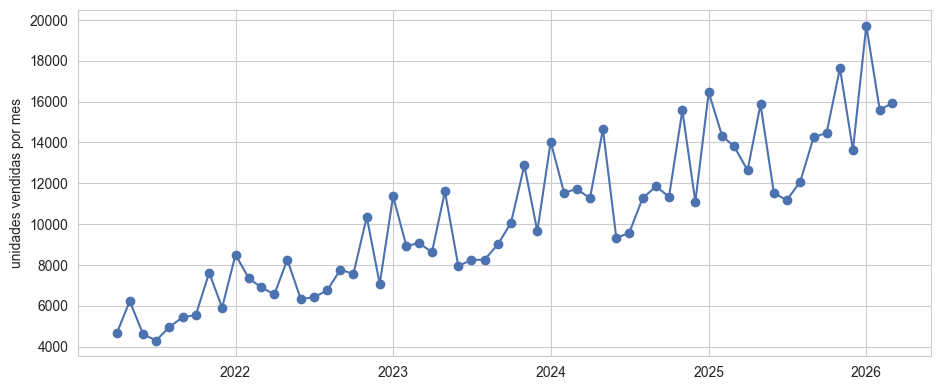

In [16]:
unidades_mes = suplementos.set_index("fecha")["unidades_vendidas"].resample("MS").sum()

print(f"{len(unidades_mes)} meses | del {unidades_mes.index[0]:%m/%Y} al {unidades_mes.index[-1]:%m/%Y}")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(unidades_mes.index, unidades_mes.values, marker="o", color="#4C72B0")
ax.set_ylabel("unidades vendidas por mes")
plt.show()

**Se ve a simple vista:**

- **Tendencia creciente.** Las ventas anuales fueron de unas 90.000 unidades en 2022, 116.000 en 2023, 143.000 en 2024 y 168.000 en 2025. Crece todos los años, aunque cada vez menos en porcentaje (29%, 24%, 17%): sube una cantidad parecida de unidades por año, no un porcentaje fijo. Guardate esto para la sección 12.
- **Estacionalidad.** Todos los años hay picos en enero, mayo y noviembre, y valles en junio, julio y agosto. Enero es el efecto "propósitos de año nuevo"; mayo y noviembre son Hot Sale y Cyber Monday con Black Friday. Esos eventos caen siempre en la misma época, así que para un modelo son **estacionalidad**, no ruido.
- **Ruido.** Hay, pero chico: el patrón se repite año a año con bastante regularidad.

¿Qué le diríamos a la gerencia si solo mirara el promedio mensual? Que compre lo mismo todos los meses, y esta serie muestra que eso sería un error.

---
## 9. Componentes: nivel, tendencia, estacionalidad y ruido

La teoría dice que toda serie se puede pensar como la suma (o el producto) de piezas: **nivel**, **tendencia**, **estacionalidad**, **ciclos** y **ruido**. Con solo cinco años de datos no podemos identificar ciclos (por ejemplo, los económicos), así que miramos las otras tres. `seasonal_decompose` las separa por nosotros.

Una decisión técnica: usamos el modo **multiplicativo**. En un modelo aditivo, la estacionalidad es "enero suma 3.000 unidades"; en uno multiplicativo es "enero vende un 25% más que el promedio". Como el negocio crece, la diferencia entre un mes bueno y uno malo **también crece** (en 2022 enero superaba a junio por unas 2.000 unidades; en la última temporada, enero de 2026 contra junio de 2025, por más de 8.000). Eso es típico de estacionalidad multiplicativa.

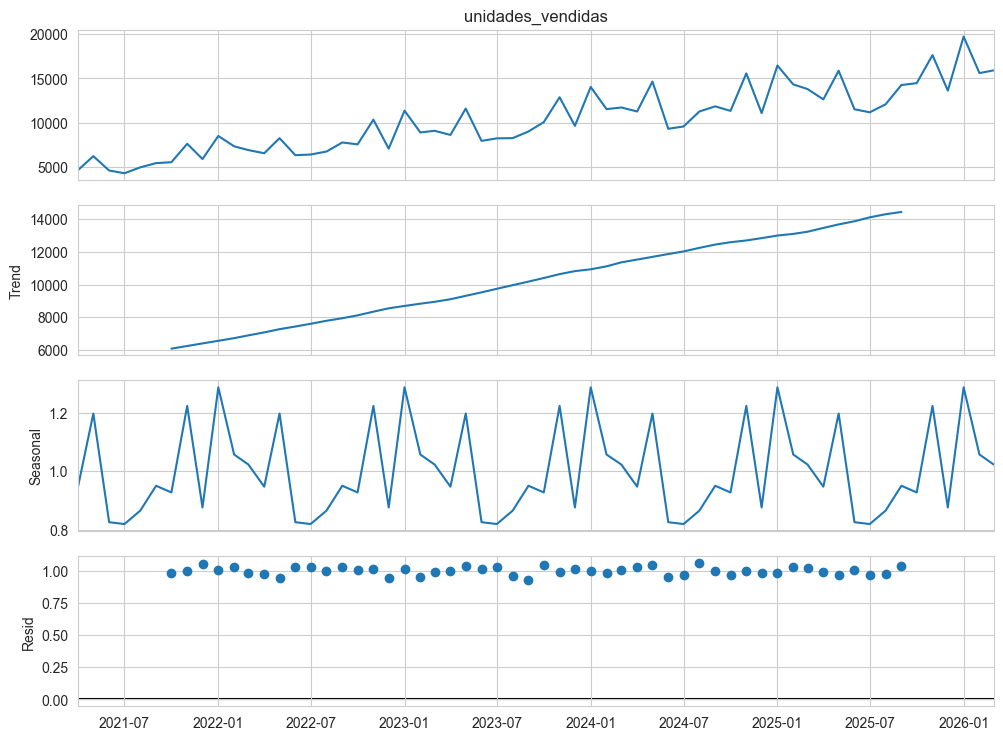

In [17]:
descomposicion = seasonal_decompose(unidades_mes, model="multiplicative", period=12)

fig = descomposicion.plot()
fig.set_size_inches(11, 8)
plt.show()

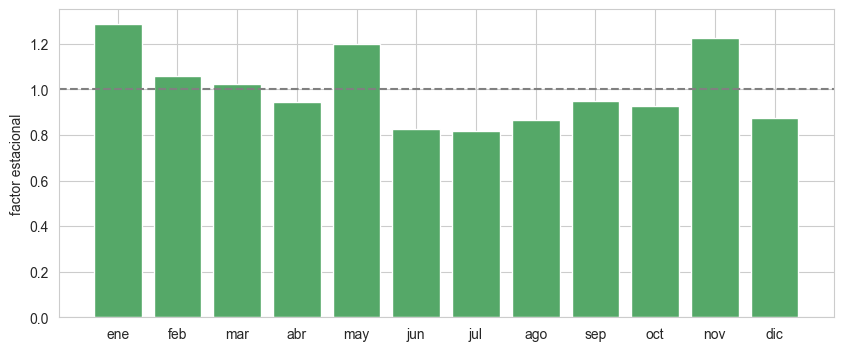

In [18]:
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

# el factor de cada mes se repite igual todos los años: nos quedamos con uno por mes
factores = descomposicion.seasonal.groupby(descomposicion.seasonal.index.month).first()
factores.index = MESES

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(factores.index, factores.values, color="#55A868")
ax.axhline(1, color="gray", linestyle="--")
ax.set_ylabel("factor estacional")
plt.show()

**Cómo leer los cuatro paneles:** arriba la serie original; después la **tendencia** (sube de unas 6.000 a unas 14.500 unidades por mes, y le faltan los primeros y últimos meses porque se calcula con un promedio centrado de 12 meses); la **estacionalidad** (el patrón que se repite idéntico todos los años) y el **residuo**, que es lo que ninguna de las dos explica: el ruido.

**En el gráfico de barras, cada barra dice cuánto se desvía ese mes de la tendencia.** Enero es 1,29: vende un 29% más que lo que marca la tendencia. Mayo (1,20) y noviembre (1,22) también están muy arriba. Junio y julio (0,83 y 0,82) venden casi un 18% menos. Y diciembre, que es el mes de las fiestas, sorprendentemente es flojo (0,88): para los suplementos, no es temporada alta.

Fijate en el trimestre que nos interesa: **abril (0,95), mayo (1,20) y junio (0,83)** tiene el pico del año y uno de los valles. Comprar el mismo stock los tres meses sería un error seguro.

---
## 10. Cómo evaluamos: train y test por fecha

Para saber si un modelo sirve hay que probarlo con datos que no vio. En las clases anteriores separábamos filas al azar; acá **no**: si el modelo entrena con meses del futuro, hace trampa. Entrenamos con los **primeros 48 meses** y evaluamos sobre los **últimos 12**, un ciclo completo de estacionalidad. El modelo pronostica ese año entero sin ver ningún dato de él.

Medimos el error de tres maneras: **MAE** (cuántas unidades nos equivocamos por mes, en promedio), **RMSE** (lo mismo, pero castigando más los errores grandes) y **MAPE** (el error como porcentaje de lo vendido). Para hablar con negocio, el MAPE es el más fácil de comunicar.

In [19]:
entrenamiento = unidades_mes.iloc[:48]
prueba = unidades_mes.iloc[48:]

print(f"entrenamiento: {entrenamiento.index[0]:%m/%Y} a {entrenamiento.index[-1]:%m/%Y}")
print(f"prueba: {prueba.index[0]:%m/%Y} a {prueba.index[-1]:%m/%Y}")

entrenamiento: 04/2021 a 03/2025
prueba: 04/2025 a 03/2026


In [20]:
def evaluar(real, pronostico):
    error = real - pronostico
    return {
        "MAE (unidades)": error.abs().mean(),
        "RMSE (unidades)": np.sqrt((error ** 2).mean()),
        "MAPE (%)": (error.abs() / real).mean() * 100,
    }


def graficar(pronosticos, titulo):
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(entrenamiento.index, entrenamiento.values, color="gray", label="entrenamiento")
    ax.plot(prueba.index, prueba.values, marker="o", color="black", label="real")
    for i, (nombre, serie) in enumerate(pronosticos.items()):
        ax.plot(serie.index, serie.values, marker="o", linestyle="--", color=COLORES[i], label=nombre)
    ax.set_title(titulo)
    ax.set_ylabel("unidades por mes")
    ax.legend()
    plt.show()


pronosticos = {}

---
## 11. Los modelos simples: naive, media acumulada y media móvil

Arrancamos por lo más básico. Son tres maneras de contestar "¿cuánto vamos a vender?" sin ningún modelo sofisticado:

- **Naive:** el próximo mes va a ser igual al último que vimos.
- **Media acumulada:** el promedio de todo el historial.
- **Media móvil:** el promedio de los últimos `k` meses (usamos k = 3, un trimestre).

Parecen ingenuos, pero cumplen un rol clave: son el **piso de comparación**. Si un modelo complejo no le gana al naive, no justifica su complejidad.

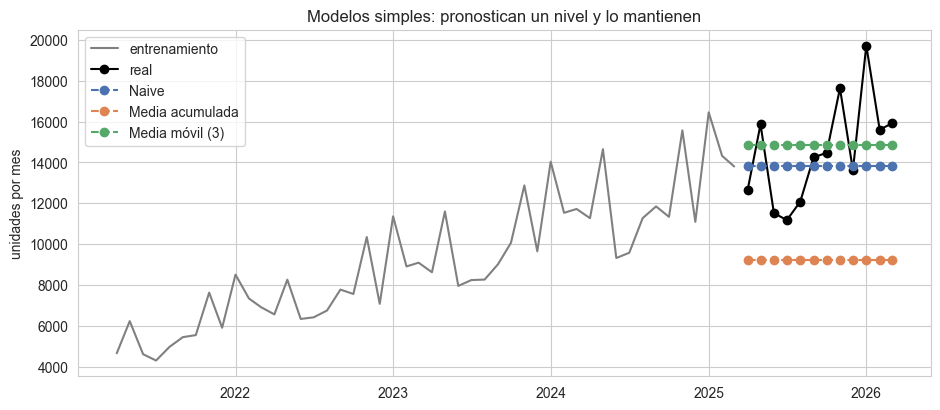

In [21]:
K_MOVIL = 3

pronosticos["Naive"] = pd.Series(entrenamiento.iloc[-1], index=prueba.index)
pronosticos["Media acumulada"] = pd.Series(entrenamiento.mean(), index=prueba.index)
pronosticos["Media móvil (3)"] = pd.Series(entrenamiento.iloc[-K_MOVIL:].mean(), index=prueba.index)

graficar(pronosticos, "Modelos simples: pronostican un nivel y lo mantienen")

In [22]:
resultados = {}
for nombre, serie in pronosticos.items():
    resultados[nombre] = evaluar(prueba, serie)

pd.DataFrame(resultados).T.round(1)

,MAE (unidades),RMSE (unidades),MAPE (%)
Naive,2068.4,2563.0,13.8
Media acumulada,5321.4,5860.0,34.8
Media móvil (3),2058.3,2474.5,14.7


**Tres líneas planas.** Ninguno de los tres ve que el negocio sube ni que hay picos y valles.

- **La media acumulada es la peor (MAPE de 34,8%).** Arrastra el pasado lejano: el negocio de 2021 vendía muchísimo menos que el de hoy, así que el promedio histórico subestima todos los meses.
- **Naive y media móvil quedan en 14% a 15%.** Mejor, porque se pegan al último nivel. Pero siendo líneas rectas, le pifian a cada pico y a cada valle: aciertan solo en los meses en que la serie casualmente cruza esa línea.

Este **13,8% del naive es el piso a superar**. Y confirma lo que dice el PDF: estos modelos "solo miden nivel".

---
## 12. Holt y Holt-Winters: tendencia y estacionalidad

Los tres modelos anteriores "solo miden nivel". Los modelos de **suavizado exponencial** agregan lo que faltaba:

- **Holt:** nivel + **tendencia** (cuánto sube o baja el nivel en cada período).
- **Holt-Winters:** nivel + tendencia + **estacionalidad**.

Tres decisiones técnicas: la tendencia es aditiva (el negocio sube unas unidades por mes, no un porcentaje); `seasonal_periods=12` porque la estacionalidad es anual y los datos son mensuales; y para la estacionalidad probamos **aditiva y multiplicativa**, que es la pregunta que nos dejó la sección 9.

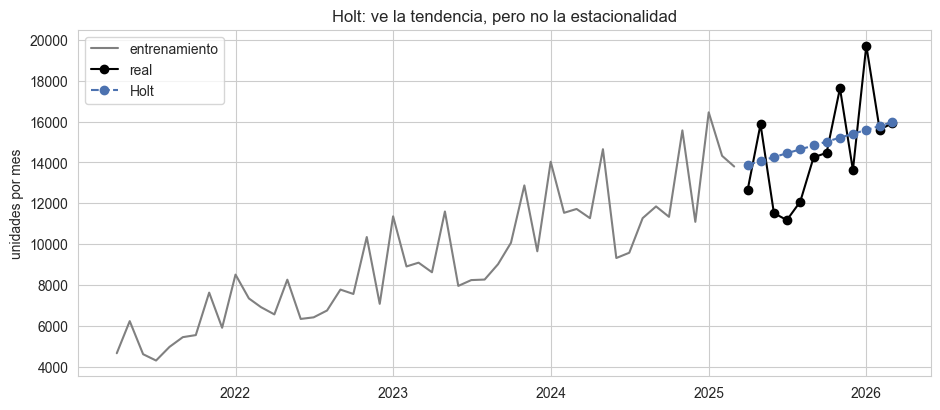

In [23]:
holt = ExponentialSmoothing(entrenamiento, trend="add").fit()
pronosticos["Holt"] = holt.forecast(12)

graficar({"Holt": pronosticos["Holt"]}, "Holt: ve la tendencia, pero no la estacionalidad")

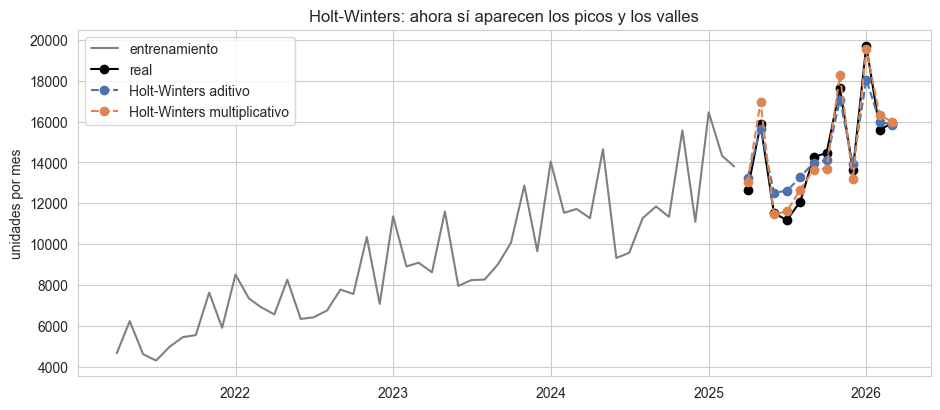

In [24]:
hw_aditivo = ExponentialSmoothing(entrenamiento, trend="add", seasonal="add", seasonal_periods=12).fit()
hw_multiplicativo = ExponentialSmoothing(entrenamiento, trend="add", seasonal="mul", seasonal_periods=12).fit()

pronosticos["Holt-Winters aditivo"] = hw_aditivo.forecast(12)
pronosticos["Holt-Winters multiplicativo"] = hw_multiplicativo.forecast(12)

graficar({"Holt-Winters aditivo": pronosticos["Holt-Winters aditivo"],
          "Holt-Winters multiplicativo": pronosticos["Holt-Winters multiplicativo"]},
         "Holt-Winters: ahora sí aparecen los picos y los valles")

In [25]:
resultados = {}
for nombre, serie in pronosticos.items():
    resultados[nombre] = evaluar(prueba, serie)

pd.DataFrame(resultados).T.round(1)

,MAE (unidades),RMSE (unidades),MAPE (%)
Naive,2068.4,2563.0,13.8
Media acumulada,5321.4,5860.0,34.8
Media móvil (3),2058.3,2474.5,14.7
Holt,1776.7,2167.0,12.7
Holt-Winters aditivo,670.3,838.6,4.9
Holt-Winters multiplicativo,502.5,578.7,3.5


**Holt (12,7%) casi no mejora al naive (13,8%).** Agregar tendencia sola ayuda poco, porque la serie oscila mucho más de lo que crece en un año: el pico de enero está un 29% arriba de la tendencia.

**Con Holt-Winters el error cae a 4,9% (aditivo) y 3,5% (multiplicativo).** El salto grande no viene de la tendencia sino de la **estacionalidad**. Y el multiplicativo gana, como anticipaba la descomposición: la amplitud de los picos crece junto con el nivel del negocio. Un MAPE de 3,5% equivale a equivocarnos en unas 500 unidades por mes sobre una venta de unas 14.500.

---
## 13. ARIMA y SARIMA

El último escalón son los modelos más complejos. **ARIMA** pronostica a partir de tres ingredientes: **AR** (los valores pasados de la serie), **I** (las diferencias, para volver la serie estable: "cuánto vendí comparado con el anterior") y **MA** (los errores pasados del modelo). Se escribe `(p, d, q)`: cuántos rezagos de cada tipo usa. **SARIMA** repite lo mismo para la memoria estacional: no solo mira qué pasó el mes pasado, también qué suele pasar en este mismo mes de otros años. Se escribe `(P, D, Q, m)`, con `m = 12` para datos mensuales.

Decisiones técnicas:

- Para ARIMA usamos `(1, 1, 1)`, el punto de partida más habitual.
- Para SARIMA usamos `(0, 1, 1)(0, 1, 1, 12)`, conocido como **modelo "airline"**: es el clásico para series mensuales con tendencia y estacionalidad.
- **Cómo se eligen los órdenes** (con gráficos de autocorrelación o criterios como el AIC) es un tema aparte que el PDF no cubre. Acá fijamos órdenes razonables y comparamos.

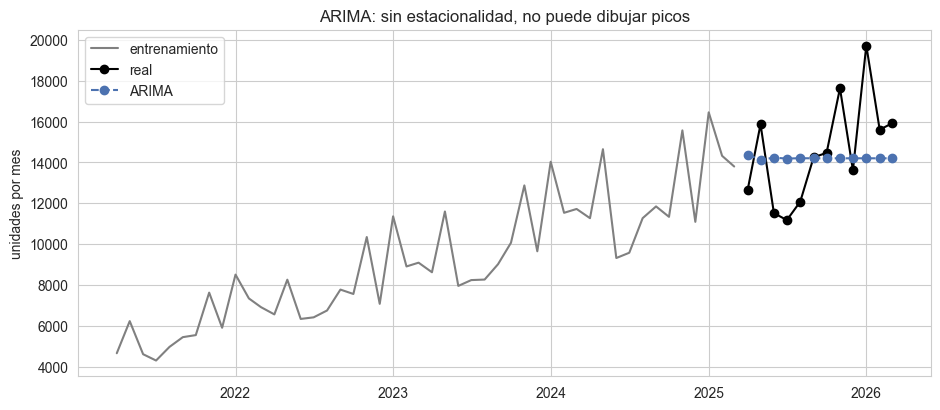

In [26]:
arima = SARIMAX(entrenamiento, order=(1, 1, 1)).fit(disp=False)
pronosticos["ARIMA"] = arima.forecast(12)

graficar({"ARIMA": pronosticos["ARIMA"]}, "ARIMA: sin estacionalidad, no puede dibujar picos")

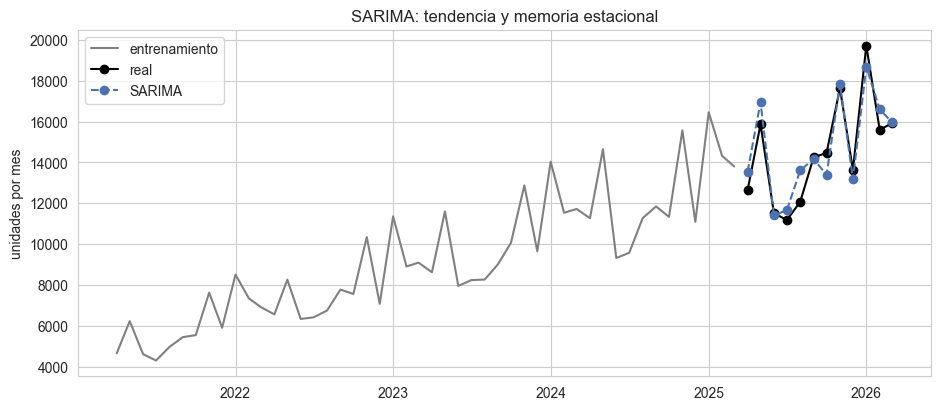

In [27]:
# start_params: con solo 48 meses statsmodels no puede calcular solo los valores iniciales y avisa
sarima = SARIMAX(entrenamiento, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
sarima = sarima.fit(start_params=[0, 0, entrenamiento.var()], disp=False)
pronosticos["SARIMA"] = sarima.forecast(12)

graficar({"SARIMA": pronosticos["SARIMA"]}, "SARIMA: tendencia y memoria estacional")

**ARIMA (13,9%) queda igual de mal que el naive:** su pronóstico es una recta casi plana. Sin componente estacional no puede dibujar picos ni valles, por más sofisticado que sea. Es el argumento del PDF: ARIMA es para series **sin estacionalidad marcada**, y esta tiene mucha.

**SARIMA (4,7%) baja el error a un tercio.** La diferencia entre los dos modelos es solo la memoria estacional.

---
## 14. Comparación y decisión de stock

Ponemos los ocho modelos lado a lado, ordenados por error.

In [28]:
resultados = {}
for nombre, serie in pronosticos.items():
    resultados[nombre] = evaluar(prueba, serie)

comparacion = pd.DataFrame(resultados).T.sort_values("MAPE (%)")
comparacion.round(1)

,MAE (unidades),RMSE (unidades),MAPE (%)
Holt-Winters multiplicativo,502.5,578.7,3.5
SARIMA,671.0,821.2,4.7
Holt-Winters aditivo,670.3,838.6,4.9
Holt,1776.7,2167.0,12.7
Naive,2068.4,2563.0,13.8
ARIMA,2024.3,2492.9,13.9
Media móvil (3),2058.3,2474.5,14.7
Media acumulada,5321.4,5860.0,34.8


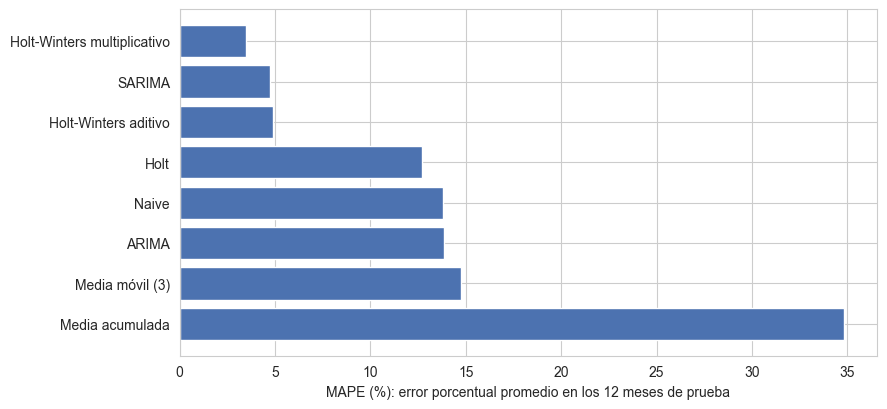

In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(comparacion.index, comparacion["MAPE (%)"], color="#4C72B0")
ax.invert_yaxis()
ax.set_xlabel("MAPE (%): error porcentual promedio en los 12 meses de prueba")
plt.show()

**Los tres primeros son los tres que incorporan estacionalidad:** Holt-Winters multiplicativo (3,5%), SARIMA (4,7%) y Holt-Winters aditivo (4,9%). Los cinco que no la tienen quedan entre 12,7% y 34,8%, muy lejos.

**La lección no es "gana el modelo más complejo".** ARIMA, que es complejo, empata con el naive. Gana el que **captura la estructura que tiene la serie**.

Y una advertencia de honestidad: entre los tres primeros la diferencia es de poco más de un punto, y con un único año de prueba eso no es concluyente. Por eso, para decidir, no nos quedamos con un solo modelo: usamos dos y los cruzamos.

### Del pronóstico a la decisión

Elegido el modelo, falta lo que le importa a la gerencia: **¿cuánto compramos para abril, mayo y junio de 2026?** Reentrenamos con los **60 meses completos** (ahora sí podemos usar el último año, porque ya no hay nada que evaluar) y pronosticamos los 3 meses que vienen. Como verificación, comparamos el resultado con SARIMA, que además nos da un **rango**: no un número, sino un intervalo en el que esperamos que caiga la venta.

In [30]:
modelo_final = ExponentialSmoothing(unidades_mes, trend="add", seasonal="mul", seasonal_periods=12).fit()
sarima_final = SARIMAX(unidades_mes, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
sarima_final = sarima_final.fit(start_params=[0, 0, unidades_mes.var()], disp=False)

futuro = sarima_final.get_forecast(3)
rango = futuro.conf_int(alpha=0.2)

proximos = pd.DataFrame({
    "Holt-Winters": modelo_final.forecast(3),
    "SARIMA": futuro.predicted_mean,
    "SARIMA piso (80%)": rango.iloc[:, 0],
    "SARIMA techo (80%)": rango.iloc[:, 1],
})
proximos.index = proximos.index.strftime("%m/%Y")

proximos.round(0)

,Holt-Winters,SARIMA,SARIMA piso (80%),SARIMA techo (80%)
04/2026,14877.0,14825.0,14013.0,15637.0
05/2026,19059.0,18061.0,17248.0,18873.0
06/2026,13219.0,13681.0,12869.0,14493.0


In [31]:
# ¿Qué tan bueno fue ese tipo de intervalo? Lo probamos con el SARIMA entrenado solo con train
intervalo_prueba = sarima.get_forecast(12).conf_int(alpha=0.2)
piso = intervalo_prueba.iloc[:, 0].values
techo = intervalo_prueba.iloc[:, 1].values

adentro = (prueba.values >= piso) & (prueba.values <= techo)
print(f"La venta real cayó dentro del intervalo del 80% en {adentro.sum()} de los {len(prueba)} meses de prueba")

La venta real cayó dentro del intervalo del 80% en 6 de los 12 meses de prueba


**Los dos modelos coinciden en abril (14.877 contra 14.825) y en junio (13.219 contra 13.681), y difieren en mayo** (19.059 contra 18.061), que justo es el mes de Hot Sale y el que más plata mueve. Son dos pronósticos razonables con 1.000 unidades de diferencia: esa es **incertidumbre real**, no un error de cálculo.

El rango del SARIMA debería leerse así: "esperamos que 8 de cada 10 veces la venta caiga dentro de este intervalo". Para mayo, entre 17.248 y 18.873. Y fijate que el pronóstico de Holt-Winters para mayo queda **por encima** del techo del SARIMA. Si nos quedamos con uno solo, no nos enteramos de esa discrepancia.

**Pero ojo con el rango: es más optimista de lo que parece.** Tiene el mismo ancho en los tres meses, y la celda de arriba muestra que en el año de prueba la venta real cayó adentro del intervalo en solo 6 de los 12 meses, no en 8 de cada 10. Un intervalo mide la incertidumbre **que el modelo cree tener**, no la que realmente hay. Usalo como un piso de incertidumbre, no como una garantía.

### Pausa: pizarrón 3 — ¿Cuánto stock compramos?

El pronóstico es un número; la decisión es otra cosa. Armamos en el pizarrón el **colchón de seguridad** (cuánto más compramos por encima del pronóstico) discutiendo el costo de cada error:

- Si nos **sobra** stock: plata inmovilizada, riesgo de vencimiento (son suplementos).
- Si nos **falta** stock: ventas perdidas y clientes que se van a la competencia.
- ¿Los dos errores cuestan lo mismo? ¿Cambia la respuesta para un mes común y para mayo, con Hot Sale?
- ¿Con qué porcentaje de colchón nos sentimos cómodos, sabiendo que en el test nos equivocamos en promedio un 3% a 5% por mes?

Cargamos la decisión en `COLCHON`.

In [32]:
COLCHON = 0.05  # lo decide la clase en el pizarrón

compra = proximos[["Holt-Winters", "SARIMA"]].mean(axis=1) * (1 + COLCHON)

print(f"Stock sugerido para el trimestre: {compra.sum():,.0f} unidades (pronóstico + {COLCHON:.0%} de colchón)")
compra.round(0)

Stock sugerido para el trimestre: 49,204 unidades (pronóstico + 5% de colchón)


04/2026    15594.0
05/2026    19488.0
06/2026    14123.0
dtype: float64

**Con el promedio de los dos modelos y un 5% de colchón, la compra del trimestre es de unas 49.200 unidades** (unas 46.900 sin colchón). Mayo concentra casi el 40% de esa compra.

Pregunta para discutir: ¿tiene sentido el **mismo** 5% para los tres meses? Mayo es el mes donde más difieren los modelos y donde más cuesta quedarse sin stock. Cambien `COLCHON` y vuelvan a correr, o prueben usar el techo del SARIMA solo para mayo.

---
## 15. Cierre

**Qué hicimos.** Con un único dataset respondimos dos preguntas distintas. En la **Parte A** resumimos 16 indicadores correlacionados en 3 componentes que conservan la mayor parte de la información. En la **Parte B** armamos una serie mensual, la descompusimos y probamos ocho modelos hasta encontrar uno que le gana por mucho al sentido común.

**Qué llevarse de PCA:**

- **Siempre estandarizar.** Sin escalar, la variable de mayor magnitud domina todo y el PCA no resume nada.
- **La cantidad de componentes se decide con la varianza acumulada (80% a 95%) y con el negocio**, no con una fórmula.
- **Los componentes son recetas, no variables.** Ponerles nombre es trabajo humano y a veces cuesta.
- **PCA no mira el objetivo.** Conserva varianza, no necesariamente la información que sirve para predecir. Por eso siempre se compara con y sin PCA.
- **Se pierde interpretabilidad.** Si la gerencia necesita saber "cuánto mejora el NPS por cada día menos de entrega", un componente no se lo puede decir.

**Qué llevarse de series temporales:**

- **El orden importa:** train y test por fecha, nunca al azar.
- **Antes de modelar, descomponer.** Ver tendencia y estacionalidad nos dice qué familia de modelo necesitamos.
- **Los modelos simples son el piso.** Un modelo complejo tiene que ganarle al naive para justificarse.
- **Un modelo que no ve la estacionalidad no sirve para una serie estacional**, por sofisticado que sea (ARIMA no le ganó ni al naive; SARIMA le ganó por mucho).
- **El pronóstico no es la decisión.** Entre el número y el stock que compramos están el colchón y el costo de cada tipo de error.

**Qué vigilar:**

- Los modelos asumen que **el futuro se parece al pasado**: el mismo crecimiento y el mismo calendario de eventos. Si cambia el contexto (una devaluación, un competidor nuevo, un Hot Sale que se mueve de fecha), el pronóstico no se entera.
- Con cinco años de historia hay solo cinco repeticiones del ciclo anual para aprender la estacionalidad. Más historia, mejor estimación.
- Los intervalos de confianza de un modelo son tan buenos como el modelo: el del SARIMA prometía 80% y en la prueba cubrió la mitad de los meses. Mejor tratarlo como un piso de incertidumbre.

**Gancho a la próxima clase.** La Clase 13 es el **repaso para el examen**, con el simulacro. Es el momento de juntar todo lo que vimos en el cuatrimestre: desde la primera visualización hasta PCA y series temporales.